In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyvista as pv
from desmin_reconstruction.plotting.lineplots import line_and_bandplot
from desmin_reconstruction.plotting.renderings import (
    render_boundingsquare,
    render_pointcloud,
)
from desmin_reconstruction.preprocessing.bbox import BoundingSquare, filter_bounded
from desmin_reconstruction.voronoi import random_uniform_like, VoronoiAnalysis
from tqdm import tqdm


plt.rc("font", size=12)
plt.rc("grid", linestyle="--", color="lightgray")
plt.rc("axes.spines", right=False, top=False)
pv.set_jupyter_backend("static")

COLOR_DICT = {"desmin": "#FF0000", "actinin": "#00FF00"}

datadir = Path("../data/")

## Import and visualize dSTORM raw data

In [2]:
filepath = datadir / "STORM/desmin_alphaactinin_2.5um.csv"
df = pl.read_csv(filepath)
df = df.with_columns(*[pl.col(i) / 1000 for i in ("x", "y", "z")])
df = df.with_columns(*[pl.col(i) - pl.col(i).min() for i in ("x", "y", "z")])
df = df.filter((pl.col("x") <= 19.0) & (pl.col("y") <= 19.0))
points = {
    name: df_.select(["x", "y", "z"]).to_numpy()
    for name, df_ in zip(("desmin", "actinin"), df.partition_by("probe"))
}


2026-01-30 15:52:01.879 (  82.774s) [    1550028C8740]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


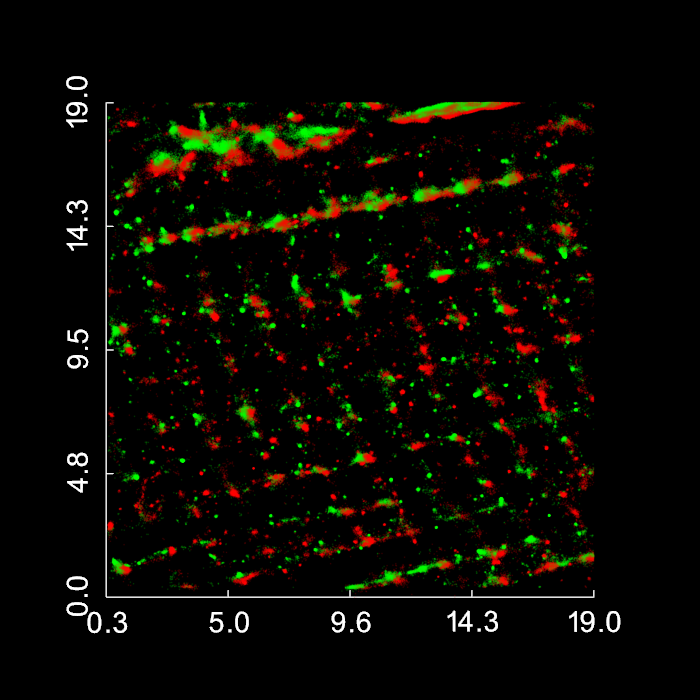

In [3]:
p = pv.Plotter(notebook=True, window_size=(700, 700))
for name, coords in points.items():
    p = render_pointcloud(p, coords, color=COLOR_DICT[name], opacity=0.2)

p.show_bounds(
    color="white",
    grid=None,
    bold=False,
    font_size=22,
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    show_zaxis=False,
    xtitle="",
    ytitle="",
)
p.show()


In [8]:
out = df.partition_by("probe")
voros = [VoronoiAnalysis(o.select(["x", "y", "z"]).to_numpy()) for o in out]
voro_vols = [v.region_volumes for v in voros]

100%|██████████| 123728/123728 [00:34<00:00, 3603.19it/s]


In [9]:
def determine_threshold(localizations, n_trials: int = 10, seed: int = 0):
    rng = np.random.default_rng(seed)
    volumes = []
    for _ in tqdm(range(n_trials)):
        voro_rand = VoronoiAnalysis(random_uniform_like(localizations, rng))
        volumes.append(voro_rand.region_volumes)
    return volumes


voro_vol_rands = [determine_threshold(v.points) for v in voros]

100%|██████████| 10/10 [07:06<00:00, 42.69s/it]


In [10]:
voro_vol_rands_ = [np.stack(v, axis=0) for v in voro_vol_rands]
for v in voro_vol_rands_:
    print(v.shape)

(10, 134248)
(10, 123728)


In [11]:
savepath = datadir / f"results/{filepath.stem}_voronoi_volumes_small.npz"
if not savepath.exists():
    np.savez(
        savepath,
        desmin=voro_vols[0],
        alpha_actinin=voro_vols[1],
        desmin_random=voro_vol_rands_[0],
        alpha_actinin_random=voro_vol_rands_[1],
    )

In [4]:
voronoi_volumes = np.load(
    datadir / "results/desmin_alphaactinin_2.5um_voronoi_volumes_small.npz"
)

In [5]:
def histogram_fixed_binsize(values, bin_size, min_value=0.0, max_value=np.inf):
    values_valid = values[~np.isnan(values)]
    values_valid = np.clip(values_valid, min_value, max_value)
    bins = np.arange(min_value, max_value, bin_size)
    return np.histogram(values_valid, bins)


def internal_division_point(x1, x2, y1, y2):
    return (y1 * x2 + y2 * x1) / (y1 + y2)


def find_crossing_points(x, y1, y2):
    y_diff = y1 - y2
    x_exact_crossing = x[np.flatnonzero(y_diff == 0)]

    ind_sign_change = np.flatnonzero(y_diff[:-1] * y_diff[1:] <= 0)
    print(ind_sign_change)
    x_interped_crossing = internal_division_point(
        x[ind_sign_change],
        x[ind_sign_change + 1],
        y_diff[ind_sign_change],
        -y_diff[ind_sign_change + 1],
    )
    x_crossing = np.concatenate((x_exact_crossing, x_interped_crossing), axis=0)
    return np.sort(x_crossing)

[13]
[14]


Text(0.5, 0.01, 'Voronoi cell volume (μm³)')

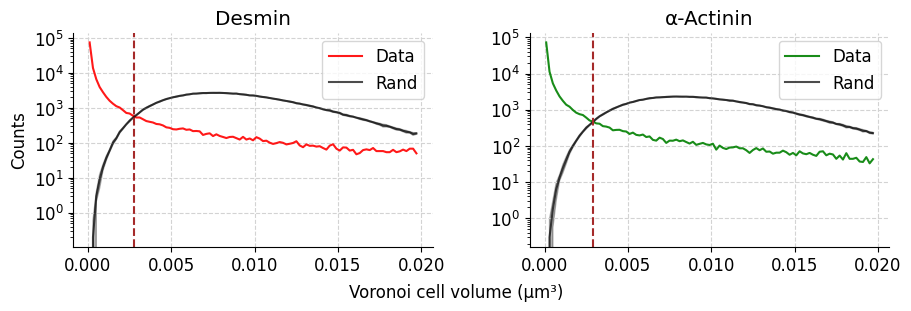

In [6]:
vol_thresholds = []

fig, axes = plt.subplots(
    1, 2, figsize=(9, 3), constrained_layout=True, gridspec_kw={"wspace": 0.1}
)
names = ("desmin", "alpha_actinin")
color_dict = {"desmin": "red", "alpha_actinin": "green"}
title_dict = {"desmin": "Desmin", "alpha_actinin": "α-Actinin"}
for ax, n in zip(axes, names):
    counts, bin_edges = histogram_fixed_binsize(
        voronoi_volumes[n], bin_size=2e-4, max_value=2e-2
    )
    counts_rand = np.stack(
        [
            histogram_fixed_binsize(vol, bin_size=2e-4, max_value=2e-2)[0]
            for vol in voronoi_volumes[f"{n}_random"]
        ],
        axis=0,
    )
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax.plot(bin_centers, counts, alpha=0.9, color=color_dict[n], label="Data")
    counts_rand_mean = np.mean(counts_rand, axis=0)
    ax = line_and_bandplot(
        ax,
        bin_centers,
        counts_rand_mean,
        np.std(counts_rand, axis=0),
        color="black",
        alpha=0.7,
        label="Rand",
    )
    ax.set_yscale("log")

    vol_thres = find_crossing_points(bin_centers, counts, counts_rand_mean)[0]
    vol_thresholds.append(vol_thres)
    ax.axvline(
        x=vol_thres,
        linestyle="--",
        color="brown",
    )
    ax.legend()
    ax.grid(ls="--", color="lightgray")
    ax.set_title(title_dict[n])
axes[0].set_ylabel("Counts")
fig.supxlabel("Voronoi cell volume (μm³)", fontsize="medium")

In [7]:
vol_thresholds

[np.float64(0.0027874921433060965), np.float64(0.0029135961930659418)]

In [9]:
coeff = 1.0
out = df.partition_by("probe")
df_filtered = [
    pl.concat(
        (
            out[i],
            pl.DataFrame({"voronoi_volume": voronoi_volumes[n]}),
        ),
        how="horizontal",
    ).filter(pl.col("voronoi_volume") <= coeff * vol_thresholds[i])
    for i, n in enumerate(("desmin", "alpha_actinin"))
]
df_filtered_total = pl.concat(df_filtered)

In [10]:
savepath_filtered = datadir / f"results/{filepath.stem}_filtered_small.csv"
if not savepath_filtered.exists():
    df_filtered_total.write_csv(savepath_filtered)

## Import filtered data

In [2]:
filepath = datadir / "results/desmin_alphaactinin_2.5um_filtered_small.csv"
df = pl.read_csv(filepath)
# df = df.with_columns(*[pl.col(i) / 1000 for i in ("x", "y", "z")])
df = df.with_columns(*[pl.col(i) - pl.col(i).min() for i in ("x", "y", "z")])

points = {
    name: df_.select(["x", "y", "z"]).to_numpy()
    for name, df_ in zip(("desmin", "actinin"), df.partition_by("probe"))
}


2026-06-27 20:37:18.704 ( 228.005s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0xef7eb00): Unable to eglMakeCurrent: 12291
2026-06-27 20:37:18.725 ( 228.026s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0xfe42ac0): Unable to eglMakeCurrent: 12291
2026-06-27 20:37:18.773 ( 228.074s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0xef7eb00): Unable to eglMakeCurrent: 12291


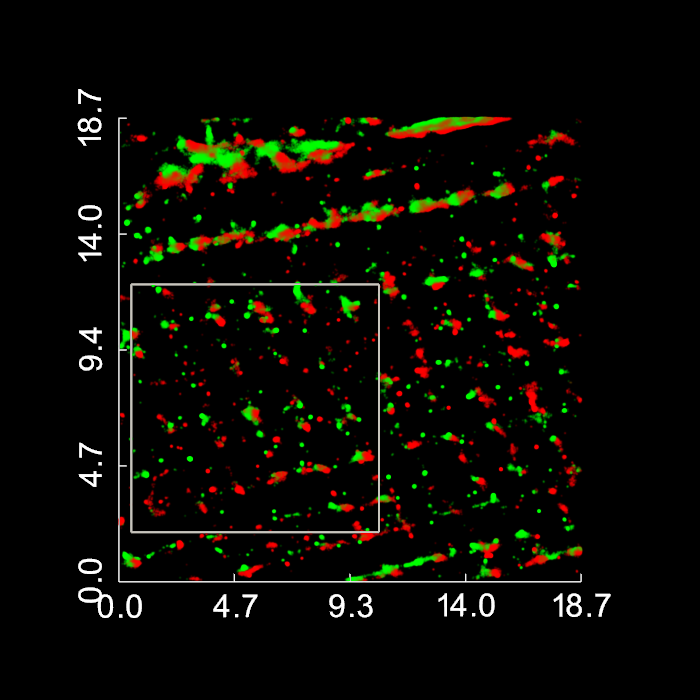

In [9]:
show_rect = True
proteins = (
    "desmin",
    "actinin",
)
p = pv.Plotter(notebook=True, window_size=(700, 700))

for name in proteins:
    p = render_pointcloud(
        p, points[name], color=COLOR_DICT[name], opacity=0.2, point_size=1.5
    )

if show_rect:
    bbox = BoundingSquare(0.5, 2, side=10)
    p = render_boundingsquare(p, bbox, line_width=2.0, color="white", z_height=10.0)

    p.enable_parallel_projection()
    p.view_xy()

p.set_background(color="black")
p.show_bounds(
    color="white",
    grid=None,
    bold=False,
    font_size=26,
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    show_zaxis=False,
    xtitle="",
    ytitle="",
)
p.show()
p.save_graphic("../figures/fig_1/1b/overlay.svg")


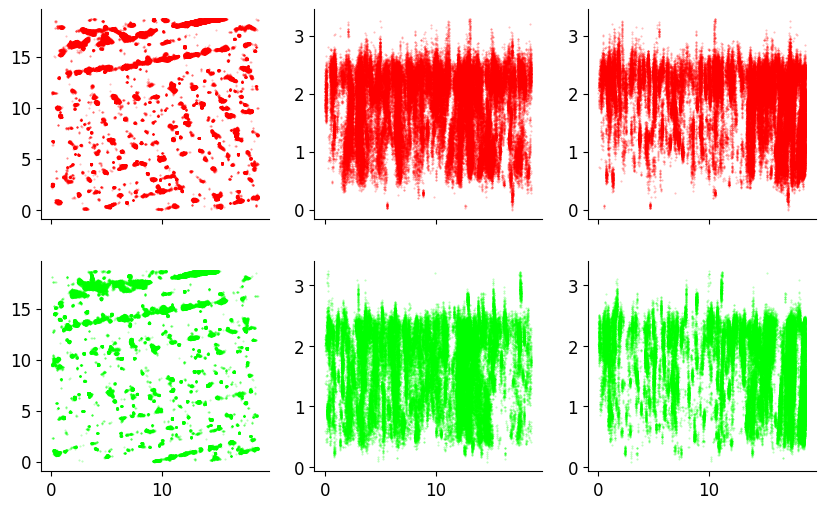

In [4]:
scatter_kwargs = {"alpha": 0.3, "s": 0.2}

fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True)
for i, protein in enumerate(("desmin", "actinin")):
    for j, (ax1, ax2) in enumerate(((0, 1), (0, 2), (1, 2))):
        axes[i, j].scatter(
            points[protein][:, ax1],
            points[protein][:, ax2],
            c=COLOR_DICT[protein],
            **scatter_kwargs,
        )

## Plot ROI

2026-06-27 20:37:44.083 ( 253.384s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0xfe42ac0): Unable to eglMakeCurrent: 12291
2026-06-27 20:37:44.103 ( 253.404s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0xfe37eb0): Unable to eglMakeCurrent: 12291
2026-06-27 20:37:44.147 ( 253.448s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0xfe42ac0): Unable to eglMakeCurrent: 12291


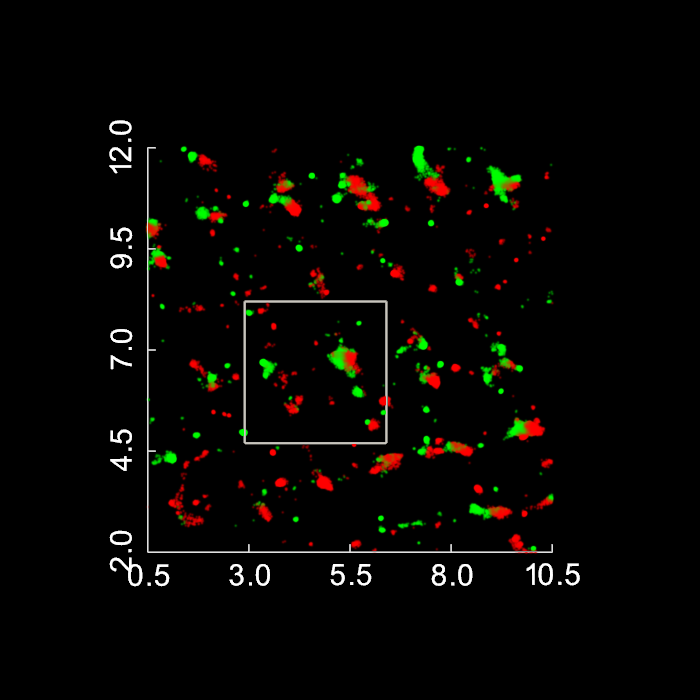

In [10]:
show_rect = True
proteins = (
    "desmin",
    "actinin",
)
p = pv.Plotter(notebook=True, window_size=(700, 700))

bbox = BoundingSquare(0.5, 2, side=10)
points_roi = {k: filter_bounded(v, bbox) for k, v in points.items()}
for name in proteins:
    p = render_pointcloud(
        p, points_roi[name], color=COLOR_DICT[name], opacity=0.4, point_size=2.0
    )

if show_rect:
    bbox2 = BoundingSquare(2.9, 4.7, side=3.5)
    p = render_boundingsquare(p, bbox2, line_width=2.0, color="white", z_height=10.0)

    p.enable_parallel_projection()
    p.view_xy()

p.set_background(color="black")
p.show_bounds(
    color="white",
    grid=None,
    bold=False,
    font_size=26,
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    show_zaxis=False,
    xtitle="",
    ytitle="",
)
p.show()
p.save_graphic("../figures/fig_1/1b/roi.svg")


2026-06-27 20:38:03.848 ( 273.149s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0x14618e90): Unable to eglMakeCurrent: 12291
2026-06-27 20:38:03.869 ( 273.170s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0x11aa87b0): Unable to eglMakeCurrent: 12291
2026-06-27 20:38:03.907 ( 273.208s) [    14F5304CB740] vtkEGLRenderWindow.cxx:674   WARN| vtkEGLRenderWindow (0x14618e90): Unable to eglMakeCurrent: 12291


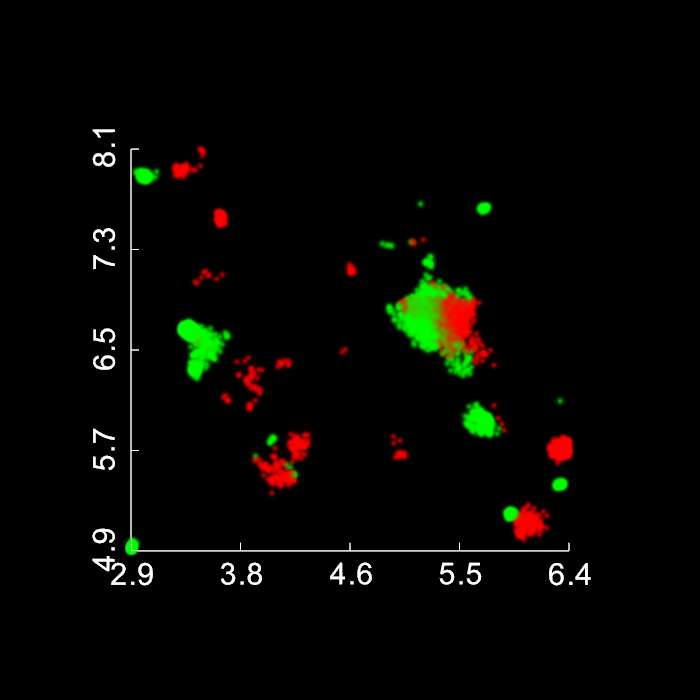

In [11]:
proteins = (
    "desmin",
    "actinin",
)
p = pv.Plotter(notebook=True, window_size=(700, 700))

bbox2 = BoundingSquare(2.9, 4.7, side=3.5)
points_roi2 = {k: filter_bounded(v, bbox2) for k, v in points_roi.items()}
for name in proteins:
    p = render_pointcloud(
        p, points_roi2[name], color=COLOR_DICT[name], opacity=0.7, point_size=4.0
    )

p.set_background(color="black")
p.show_bounds(
    color="white",
    grid=None,
    bold=False,
    font_size=26,
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    show_zaxis=False,
    xtitle="",
    ytitle="",
)
p.show()
p.save_graphic("../figures/fig_1/1b/roi2.svg")


## Align volume

In [25]:
import warnings

from desmin_reconstruction.preprocessing.storm import align_patch


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    transform_fn, metrics = align_patch(
        points,
        tilt_sweep_values=np.arange(-0.5, 0.5, 0.001),
        rotation_sweep_values=np.arange(-30, -25, 0.5),
        min_cluster_size=1000,
        min_samples=5,
    )

100%|██████████| 10/10 [00:24<00:00,  2.46s/it]


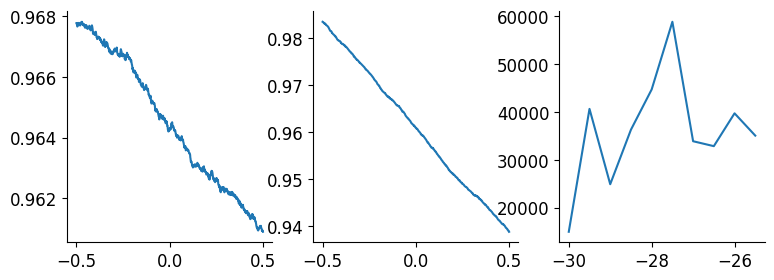

In [26]:
fig, axes = plt.subplots(1, len(metrics), figsize=(9, 3))
for ax, metric in zip(axes, metrics):
    ax.plot(*metric)

In [27]:
coords_new = transform_fn(df.select(["x", "y", "z"]).to_numpy())
df_aligned = df.with_columns(pl.from_numpy(coords_new, schema=["x", "y", "z"]))

In [28]:
points_final = {
    name: df_.select(["x", "y", "z"]).to_numpy()
    for name, df_ in zip(("desmin", "actinin"), df_aligned.partition_by("probe"))
}

In [4]:
p = pv.Plotter(notebook=True, window_size=(700, 700))
for name, coords in points_final.items():
    p = render_pointcloud(p, coords, color=COLOR_DICT[name], opacity=0.2)

p.show_bounds(
    color="white",
    grid=None,
    bold=False,
    font_size=22,
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    show_zaxis=False,
    xtitle="",
    ytitle="",
)
p.show()
# p.save_graphic("../figures/supp_fig_1b/desmin.svg")

NameError: name 'points_final' is not defined

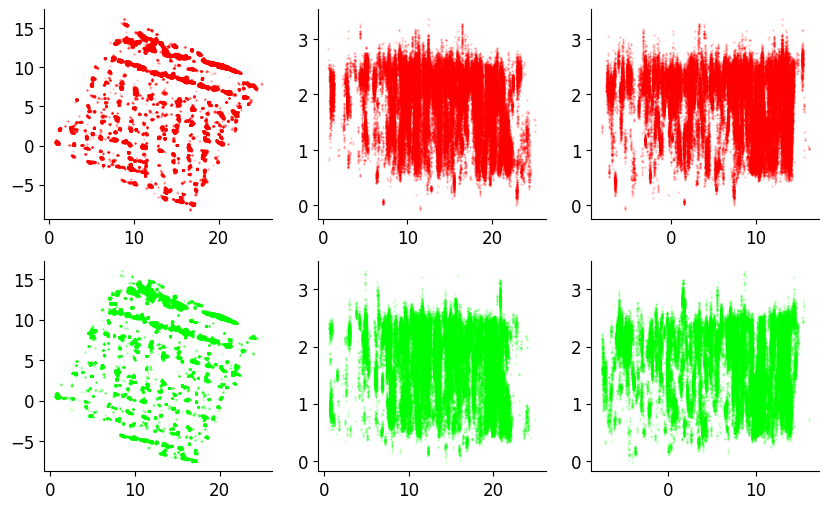

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for i, protein in enumerate(("desmin", "actinin")):
    for j, (ax1, ax2) in enumerate(((0, 1), (0, 2), (1, 2))):
        axes[i, j].scatter(
            points_final[protein][:, ax1],
            points_final[protein][:, ax2],
            c=COLOR_DICT[protein],
            **scatter_kwargs,
        )

In [ ]:
# df_aligned.write_csv("../data/results/desmin_alphaactinin_2.5um_small_aligned.csv")

## Choose 4um x 4um regions of interest

In [9]:
df = pl.read_csv("../data/results/desmin_alphaactinin_2.5um_small_aligned.csv")
points = {
    name: df_.select(["x", "y", "z"]).to_numpy()
    for name, df_ in zip(("desmin", "actinin"), df.partition_by("probe"))
}

In [10]:
x0s = (18.5, 16.5, 14.5, 14.5, 12.5, 10.5, 8.5, 6.5, 4.5, 2.5, 0.5, 4.5)
y0s = (2.0, -2.0, -6.0, 2.0, -2.0, 2.0, -2.0, 2.0, -2.0, 2.0, -2.0, 6.0)
bboxes = [BoundingSquare(x0, y0, side=4) for x0, y0 in zip(x0s, y0s)]

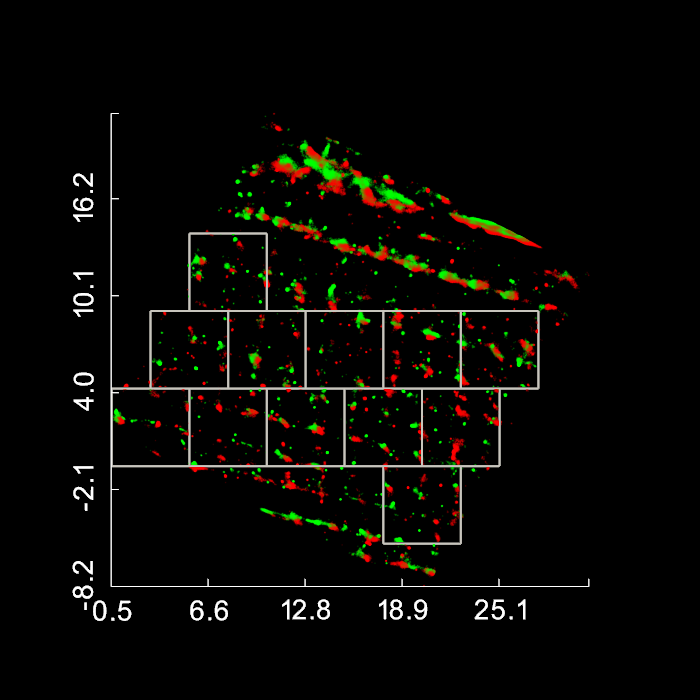

In [12]:
p = pv.Plotter(notebook=True, window_size=(700, 700))
for name, coords in points.items():
    p = render_pointcloud(p, coords, color=COLOR_DICT[name], opacity=0.2)

for bbox in bboxes:
    p = render_boundingsquare(p, bbox, line_width=2.0, color="white", z_height=10.0)

p.enable_parallel_projection()
p.view_xy()

p.show_bounds(
    color="white",
    grid=None,
    bold=False,
    font_size=22,
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    show_zaxis=False,
    xtitle="",
    ytitle="",
)


p.show()
p.save_graphic("../figures/supp_fig_2/2b.svg")